# Linear SVC Hyperparameter Tuning - PCA inputs

**Purpose:** Train and evaluate linear support vector classifiers on the first *n* principal components for every even *n* from 6 to 92, with nested cross-validation (manuscript Sections 3.2 and 4.2, Fig. 3). These are the 'SVC PCA' curves compared with the ANNs in `ML_Performance_Comparison.ipynb`.

**Per outer fold (leave one biological replicate out):**
1. Fit a `StandardScaler` and `PCA` on the training spectra only and apply them to the held-out replicate.
2. For each PC count (`npcs_exp = 92, 90, ..., 6`), keep the first *n* PCs, tune `C` (8 log-spaced values, 10$^{-3}$ to 10$^{3}$, linear kernel) with `GridSearchCV` (default 5-fold inner CV, accuracy), refit the best model on all training spectra and evaluate on the held-out replicate.

Three classifiers: species, benzoate condition (`metabolites` in the code) and culture age. `random_state = 42`.

**Output:** `Performance Dictionaries/Performance_SVC_PCA_nCV.pkl`: `{ "CV k": [ {n_PCs: {task: [X_train, y_train, X_test, y_test, y_predict, GridSearchCV, best model, confusion matrix, report]}}, fitted PCA, fitted StandardScaler ] }`.

In [1]:
# Imports (several are not used in this notebook, e.g. plotly, KernelPCA, SVR, RandomizedSearchCV, 3D plotting).
import pandas as pd
pd.DataFrame.iteritems = pd.DataFrame.items
import numpy as np
import os
import re
import pickle

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits import mplot3d
import matplotlib.ticker as mticker
import matplotlib.transforms as transforms
import matplotlib.patches as patches
import matplotlib.cm as cm

import plotly.express as px
import scipy

from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA, KernelPCA

from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.svm import SVC, SVR
from sklearn.neural_network import MLPClassifier
from sklearn import metrics
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
# Load the preprocessed dataset produced by Data_Preprocessing_Pipeline.ipynb
filename = "Preprocessed_Raman_Spectra_2025.pkl"
with open(filename, "rb") as f:
    loaded_data = pickle.load(f)
    
print(loaded_data['Spectra'].shape)

(360, 1003)


In [3]:
# Show the preprocessing settings stored with the data
loaded_data["Preprocess conditions"]

{'order': 'SI --> CS --> BSR --> SG --> ED',
 'CS': [1, 0.01],
 'BSR': [100, 1],
 'SG': [15, 2],
 'ED': [400, 1800]}

In [4]:
# Unpack the dictionary into separate arrays (spectra, wavenumbers, labels, replicate IDs)
wavenumber = loaded_data["wavenumber"]
spectral = loaded_data["Spectra"]

bacteria_species = loaded_data["species label"]
culture_age = loaded_data['culture age']
cul_cond = loaded_data["culture condition"]

biological_rep = loaded_data["biological replicate"]
technical_rep = loaded_data["technical replicate"]

In [5]:
# Translate the condition codes into readable labels: A = 0 mM benzoate, C = 20 mM benzoate
condition_dict = {"A" : "0 mM benzoate", "C" : "20 mM benzoate"}
culture_condition = []
for i in range(len(cul_cond)):
    culture_condition.append(condition_dict[cul_cond[i]])
culture_condition = np.array(culture_condition)

# Biological Replicate Seperation

In [6]:
# Build the label matrix y_data_full (one row per spectrum, three columns).
# Labels are integer-encoded in sorted order of the unique values:
#   col 0 = species:   CBG (C. glutamicum) = 0, PP (P. putida) = 1
#   col 1 = condition: 0 mM benzoate = 0, 20 mM benzoate = 1  (called 'metabolites' in the code below)
#   col 2 = culture age: 5 h = 0, 24 h = 1, 48 h = 2
# X_data_full is the matrix of preprocessed spectra (360 x 1003).
label_species = np.unique(bacteria_species)
label_condition = np.unique(culture_condition)
label_age = np.unique(culture_age)

species_dict = {}
for i in range(len(label_species)):
    species_dict[label_species[i]] = i
    
condition_dict = {}
for i in range(len(label_condition)):
    condition_dict[label_condition[i]] = i
    
age_dict = {}
for i in range(len(label_age)):
    age_dict[label_age[i]] = i
    
y_output = []
for i in range(len(bacteria_species)):
    temp = [species_dict[bacteria_species[i]],
           condition_dict[culture_condition[i]],
            age_dict[culture_age[i]]
           ]
    y_output.append(np.array(temp))

y_data_full = np.array(y_output)
X_data_full = spectral

print(X_data_full.shape, y_data_full.shape)

(360, 1003) (360, 3)


In [13]:
# Evaluate one outer fold at a given number of PCs: use the first num_pcs principal components (train_X / test_X are the already PCA-projected
# spectra), tune a linear SVC for each of the three tasks by grid search, and predict the held-out spectra.
# Returns {task: [X_train, y_train, X_test, y_test, y_predict, GridSearchCV object, best model, confusion matrix, classification report]}.
def nCV_PCA_eval(num_pcs, train_X, test_X, train_y, test_y):
    # Names of the three classification tasks. 'metabolites' = benzoate condition (0 vs 20 mM).
    names = ["species", "metabolites", "age"]
    overall_performance = {}
    rs = 42

    for j in range(len(names)):

        # Keep only the first num_pcs principal components as input features
        X_data_train = train_X[:,:num_pcs]
        y_data_train = train_y[:,j]

        X_data_test = test_X[:,:num_pcs]
        y_data_test = test_y[:,j]

        print(names[j], X_data_train.shape, y_data_train.shape)
        
        # Hyperparameter grid (Table 1): linear kernel, C = 8 log-spaced values from 1e-3 to 1e3
        param_grid = { "kernel": ["linear"],
                      "C" : np.logspace(-3, 3, 8)}

        # Support vector classifier with a fixed seed
        SVC_model = SVC(random_state = 42)

        # Inner cross-validation: GridSearchCV (5-fold by default, scored by accuracy); refit on all training spectra with the best C
        SVC_grid = GridSearchCV(SVC_model, 
                                 param_grid, 
                                 n_jobs = -1, 
                                 verbose = 0, 
                                 return_train_score = True)

        SVC_grid.fit(X_data_train, y_data_train)

        # Best model evaluated on the held-out replicate
        SVC_best_model = SVC_grid.best_estimator_
        y_predict = SVC_best_model.predict(X_data_test)

        # Test-set report and confusion matrix
        report = classification_report(y_data_test, y_predict, output_dict = True)
        con_mat = confusion_matrix(y_data_test, y_predict)

        # Store inputs, predictions, grid search, best model and metrics
        overall_performance[names[j]] = [X_data_train, y_data_train, X_data_test, y_data_test, 
                                         y_predict, SVC_grid, SVC_best_model, con_mat, report]

    return overall_performance

In [9]:
# Outer loop = leave-one-biological-replicate-out (3-fold CV). Each fold trains on two biological replicates and tests on the held-out one,
# so spectra from the same culture never appear in both training and test sets (manuscript Section 3.2).
# npcs_exp = every even number of PCs from 92 down to 6.
import time

uni_br = np.unique(biological_rep)
NCV_performance = {}
# PC counts to evaluate: 92, 90, ..., 6
npcs_exp = np.arange(92, 5, -2)

for i in range(len(uni_br)):
    strcv = "CV " + str(uni_br[i])
    
    print(strcv)
    
    ind_train = biological_rep != uni_br[i]
    ind_test = biological_rep == uni_br[i]
    
    train_X_full = X_data_full[ind_train,:]
    test_X_full = X_data_full[ind_test,:]
    
    # Fit the scaler and PCA on the training spectra of this outer fold only
    SS_overall = StandardScaler()
    PCA_overall = PCA()
    
    # Standardise and project training spectra, then transform the held-out spectra with the same fitted objects
    train_X_ss = SS_overall.fit_transform(train_X_full)
    test_X_ss = SS_overall.transform(test_X_full)
    
    train_X_pca = PCA_overall.fit_transform(train_X_ss)
    test_X_pca = PCA_overall.transform(test_X_ss)
    
    train_y_data = y_data_full[ind_train,:]
    test_y_data = y_data_full[ind_test,:]
    
    pca_performance = {}
    
    # Loop over PC counts (the inner 'for n in ...' below re-uses the name n harmlessly, since it is re-bound on each outer iteration)
    for n in npcs_exp:
        
        temp = nCV_PCA_eval(n, 
                            train_X_pca,
                            test_X_pca, 
                            train_y_data, 
                            test_y_data)
        
        pca_performance[n] = temp
        
        for n in list(temp.keys()):
            print(n + " accuracy: ", round(temp[n][-1]["accuracy"], 2))
        
        print("~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~")
        
    # Save, per fold: results for every PC count, the fitted PCA and scaler
    NCV_performance[strcv] = [pca_performance, PCA_overall, SS_overall]
    print("~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~")

CV 1
species (240, 92) (240,)
metabolites (240, 92) (240,)
age (240, 92) (240,)
species accuracy:  0.93
metabolites accuracy:  0.76
age accuracy:  0.84
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
species (240, 90) (240,)
metabolites (240, 90) (240,)
age (240, 90) (240,)
species accuracy:  0.94
metabolites accuracy:  0.76
age accuracy:  0.83
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
species (240, 88) (240,)
metabolites (240, 88) (240,)
age (240, 88) (240,)
species accuracy:  0.94
metabolites accuracy:  0.76
age accuracy:  0.83
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
species (240, 86) (240,)
metabolites (240, 86) (240,)
age (240, 86) (240,)
species accuracy:  0.94
metabolites accuracy:  0.74
age accuracy:  0.83
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
species (240, 84) (240,)
metabolites (240, 84) (240,)
age (240, 84) (240,)
species accuracy:  0.93
metabolites accu

species accuracy:  0.92
metabolites accuracy:  0.68
age accuracy:  0.79
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
species (240, 16) (240,)
metabolites (240, 16) (240,)
age (240, 16) (240,)
species accuracy:  0.93
metabolites accuracy:  0.68
age accuracy:  0.78
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
species (240, 14) (240,)
metabolites (240, 14) (240,)
age (240, 14) (240,)
species accuracy:  0.92
metabolites accuracy:  0.69
age accuracy:  0.78
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
species (240, 12) (240,)
metabolites (240, 12) (240,)
age (240, 12) (240,)
species accuracy:  0.92
metabolites accuracy:  0.69
age accuracy:  0.71
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
species (240, 10) (240,)
metabolites (240, 10) (240,)
age (240, 10) (240,)
species accuracy:  0.9
metabolites accuracy:  0.68
age accuracy:  0.71
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

metabolites (240, 30) (240,)
age (240, 30) (240,)
species accuracy:  0.9
metabolites accuracy:  0.74
age accuracy:  0.86
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
species (240, 28) (240,)
metabolites (240, 28) (240,)
age (240, 28) (240,)
species accuracy:  0.89
metabolites accuracy:  0.75
age accuracy:  0.88
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
species (240, 26) (240,)
metabolites (240, 26) (240,)
age (240, 26) (240,)
species accuracy:  0.9
metabolites accuracy:  0.76
age accuracy:  0.88
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
species (240, 24) (240,)
metabolites (240, 24) (240,)
age (240, 24) (240,)
species accuracy:  0.89
metabolites accuracy:  0.76
age accuracy:  0.88
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
species (240, 22) (240,)
metabolites (240, 22) (240,)
age (240, 22) (240,)
species accuracy:  0.89
metabolites accuracy:  0.75
age accuracy:  0.88


age (240, 44) (240,)
species accuracy:  0.9
metabolites accuracy:  0.76
age accuracy:  0.87
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
species (240, 42) (240,)
metabolites (240, 42) (240,)
age (240, 42) (240,)
species accuracy:  0.9
metabolites accuracy:  0.7
age accuracy:  0.86
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
species (240, 40) (240,)
metabolites (240, 40) (240,)
age (240, 40) (240,)
species accuracy:  0.9
metabolites accuracy:  0.76
age accuracy:  0.82
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
species (240, 38) (240,)
metabolites (240, 38) (240,)
age (240, 38) (240,)
species accuracy:  0.87
metabolites accuracy:  0.77
age accuracy:  0.81
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
species (240, 36) (240,)
metabolites (240, 36) (240,)
age (240, 36) (240,)
species accuracy:  0.88
metabolites accuracy:  0.76
age accuracy:  0.82
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

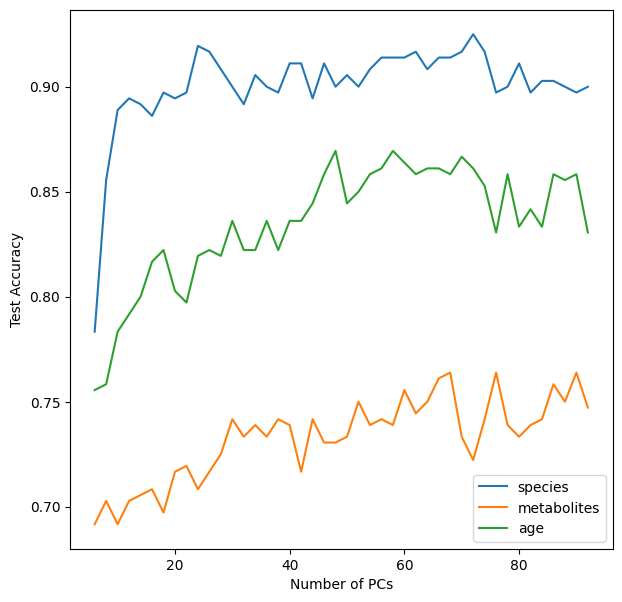

In [10]:
# Quick look: mean test accuracy over the three folds vs number of PCs for each task (the polished version is Fig. 3 in ML_Performance_Comparison.ipynb)
folds = list(NCV_performance.keys())
names = list(NCV_performance[folds[0]][0][npcs_exp[0]].keys())

plt.figure(figsize = (7,7))

for i in range(len(names)):
    acc_overall = []
    
    for n in npcs_exp:
        temp_acc = []
        
        for c in folds:
            temp_acc.append(NCV_performance[c][0][n][names[i]][-1]["accuracy"])
        
        acc_overall.append(temp_acc)
        
    plt.plot(npcs_exp, np.mean(acc_overall, axis = 1), label = names[i])
    plt.xlabel("Number of PCs")
    plt.ylabel("Test Accuracy")
    plt.legend()

In [6]:
# Save the nested-CV results (input for ML_Performance_Comparison.ipynb)
my_dictionary = NCV_performance
 
# Open a file in write binary mode ('wb')
with open('Performance Dictionaries\\Performance_SVC_PCA_nCV.pkl', 'wb') as file:
    # Serialize the dictionary and write it to the file
    pickle.dump(my_dictionary, file)